# Evaluate the card detector

Compare synthetic and real photos using COCO box mAP and confidence-threshold precision/recall. This evaluates card detection; the model does not predict segmentation masks.


In [4]:
import json
from pathlib import Path

import cv2
import torch
from IPython.display import HTML, display

from set_master.paths import DINOV3_REPO_DIR, REAL_TESTSET_DIR, RUNS_DIR, SYNTHETIC_DATASETS_DIR
from set_master.training.data import CocoCardDataset
from set_master.training.evaluation import evaluate_detector
from set_master.training.model import CardDetector
from set_master.visualization import display_image


## Select checkpoint and datasets

Enter the checkpoint path and synthetic run explicitly. For a synthetic dataset used during training, set `synthetic_split_path` to that run's `split.json` to evaluate its held-out validation images. Leave it `None` for a separate synthetic test dataset.

Real annotations currently exclude deck tops and partial cards. Detections of those cards count as false positives. Several photos share scenes, including an original and its crop; the real results are not independent samples.


In [14]:
checkpoint_path = RUNS_DIR / 'card_detector' / 'version_1' / 'checkpoints' / 'last.ckpt'
synthetic_run = 'run_20261010_125004_004209'
synthetic_data = SYNTHETIC_DATASETS_DIR / synthetic_run
synthetic_split_path = None  # Set to the training run's split.json for held-out evaluation.
real_data = REAL_TESTSET_DIR

device = 'cuda'
batch_size = 8
num_workers = 0
score_threshold = 0.75
iou_threshold = 0.5
checkpoint_run = checkpoint_path.parent.parent.name if checkpoint_path.parent.name == 'checkpoints' else checkpoint_path.parent.name
evaluation_name = f'{checkpoint_run}__{checkpoint_path.stem}__{synthetic_data.name}'
output_dir = RUNS_DIR / 'card_evaluation' / evaluation_name

# Synthetic IDs to save as overlays.
synthetic_overlay_ids = []


## Load model and evaluation images


In [15]:
if not checkpoint_path.is_file():
    raise FileNotFoundError(f'Select a checkpoint: {checkpoint_path}')
if device.startswith('cuda') and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Choose device="cpu" to evaluate on CPU.')

synthetic_dataset = CocoCardDataset(synthetic_data)
real_dataset = CocoCardDataset(real_data)
real_overlay_ids = [info['id'] for info in real_dataset.images]
synthetic_image_ids = None
if synthetic_split_path is not None:
    split = json.loads(Path(synthetic_split_path).read_text())
    if Path(split['val_root']).resolve() != synthetic_data.resolve():
        raise ValueError('The selected split belongs to a different validation dataset.')
    synthetic_image_ids = split['val_image_ids']

model = CardDetector.load_from_checkpoint(
    checkpoint_path, map_location='cpu', weights_only=True,
    repo_path=str(DINOV3_REPO_DIR), initialize_pretrained=False,
).eval().to(device)
print(f'Checkpoint: {checkpoint_path}')
print(f'Device: {model.device}')
print(f'Synthetic images: {len(synthetic_image_ids) if synthetic_image_ids is not None else len(synthetic_dataset)}')
print(f'Real images: {len(real_dataset)}')
for name, dataset, selected_ids in [
    ('synthetic', synthetic_dataset, synthetic_image_ids),
    ('real', real_dataset, None),
]:
    ids = [info['id'] for info in dataset.images if selected_ids is None or info['id'] in selected_ids]
    print(f'{name} evaluation image IDs: {ids}')


Checkpoint: /home/florian/src/python/set-master/runs/card_detector/version_1/checkpoints/last.ckpt
Device: cuda:0
Synthetic images: 100
Real images: 13
synthetic evaluation image IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]
real evaluation image IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


## Evaluate

mAP averages IoU thresholds from 0.50 to 0.95. AP50, AP75 and recall@100 use all returned predictions, independent of `score_threshold`. Precision, recall and F1 use `score_threshold` and one-to-one box matching at `iou_threshold`.


In [16]:
results = {}
for name, dataset, selected_ids, overlay_ids in [
    ('synthetic', synthetic_dataset, synthetic_image_ids, synthetic_overlay_ids),
    ('real', real_dataset, None, real_overlay_ids),
]:
    print(name)
    results[name] = evaluate_detector(
        model, dataset, output_dir / name,
        image_ids=selected_ids, overlay_image_ids=tuple(overlay_ids),
        batch_size=batch_size, num_workers=num_workers,
        score_threshold=score_threshold, iou_threshold=iou_threshold,
    )

configuration = {
    'checkpoint': str(checkpoint_path.resolve()), 'device': device,
    'synthetic_data': str(synthetic_data.resolve()), 'real_data': str(real_data.resolve()),
    'synthetic_split_path': str(Path(synthetic_split_path).resolve()) if synthetic_split_path is not None else None,
    'score_threshold': score_threshold, 'iou_threshold': iou_threshold,
}
(output_dir / 'config.json').write_text(json.dumps(configuration, indent=2) + '\n')
print(f'Reports and COCO predictions: {output_dir}')


synthetic
Evaluated 100/100 images
real
Evaluated 13/13 images
Reports and COCO predictions: /home/florian/src/python/set-master/runs/card_evaluation/version_1__last__run_20261010_125004_004209


## Compare metrics


In [17]:
columns = [('map', 'mAP'), ('map_50', 'AP50'), ('map_75', 'AP75'),
           ('mar_100', 'Recall@100'), ('precision', 'Precision'), ('recall', 'Recall'), ('f1', 'F1')]
header = '<tr><th>Dataset</th><th>Images</th>' + ''.join(f'<th>{label}</th>' for _, label in columns) + '</tr>'
rows = []
for name, result in results.items():
    values = ''.join(f'<td>{result.metrics[key]:.3f}</td>' for key, _ in columns)
    rows.append(f'<tr><th>{name}</th><td>{len(result.images)}</td>{values}</tr>')
display(HTML('<table>' + header + ''.join(rows) + '</table>'))


Dataset,Images,mAP,AP50,AP75,Recall@100,Precision,Recall,F1
synthetic,100,0.936,1.000,1.000,0.958,0.976,1.000,0.988
real,13,0.374,0.655,0.401,0.446,0.795,0.596,0.681


## Per-image counts

TP = matched detections, FP = unmatched predictions, FN = missed cards.


In [18]:
dataset_to_inspect = 'real'
rows = []
for item in results[dataset_to_inspect].images:
    rows.append('<tr>' + ''.join(f'<td>{item[key]}</td>' for key in
        ('image_id', 'ground_truth', 'predictions', 'true_positives', 'false_positives', 'false_negatives')) + '</tr>')
display(HTML('<table><tr><th>ID</th><th>Cards</th><th>Predictions</th><th>TP</th><th>FP</th><th>FN</th></tr>'
             + ''.join(rows) + '</table>'))


ID,Cards,Predictions,TP,FP,FN
1,12,12,12,0,0
2,12,9,8,1,4
3,12,2,2,0,10
4,12,3,0,3,12
5,12,5,2,3,10
6,12,5,3,2,9
7,12,3,1,2,11
8,12,10,10,0,2
9,12,16,12,4,0
10,12,14,9,5,3


## Inspect overlays

Ground truth is green; predictions are red. Choose an ID included in the overlay settings, then rerun evaluation after changing those settings.


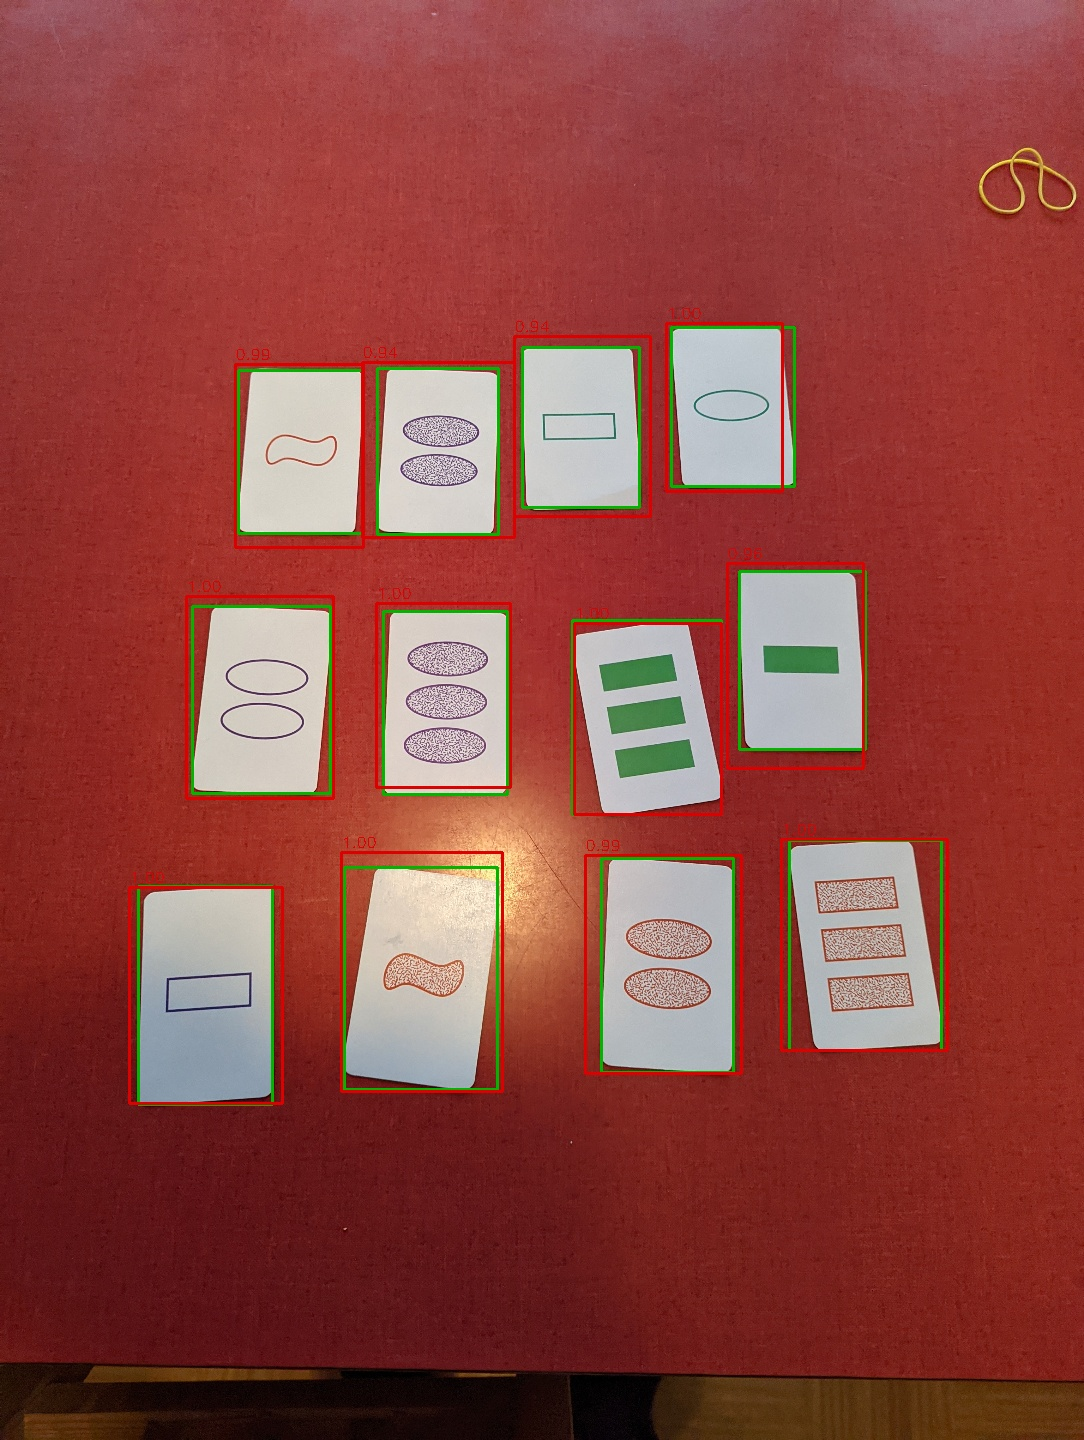

In [21]:
preview_dataset = 'real'
preview_image_id = 1
preview_path = output_dir / preview_dataset / f'overlay_{preview_image_id:06d}.jpg'
preview = cv2.imread(str(preview_path))
if preview is None:
    raise FileNotFoundError(f'Include this image ID in the overlay settings and rerun evaluation: {preview_path}')
display_image(preview)
